STUDENT PERFORMANCE ANALYSIS
Student_ID  Math  Science  Programming  Average Status
      S001    78       85           90    84.33   Pass
      S002    92       89           94    91.67   Pass
      S003    65       72           70    69.00   Pass
      S004    88       91           96    91.67   Pass
      S005    74       80           82    78.67   Pass
      S006    95       93           98    95.33   Pass
      S007    81       84           88    84.33   Pass
      S008    69       75           73    72.33   Pass
      S009    90       87           95    90.67   Pass
      S010    76       79           85    80.00   Pass
\nAVERAGE SCORE BY SUBJECT
Math           80.8
Science        83.5
Programming    87.1
dtype: float64
\nClass average: 83.8
Top student: S006
Top student's average: 95.33
Students meeting the pass threshold: 10 / 10


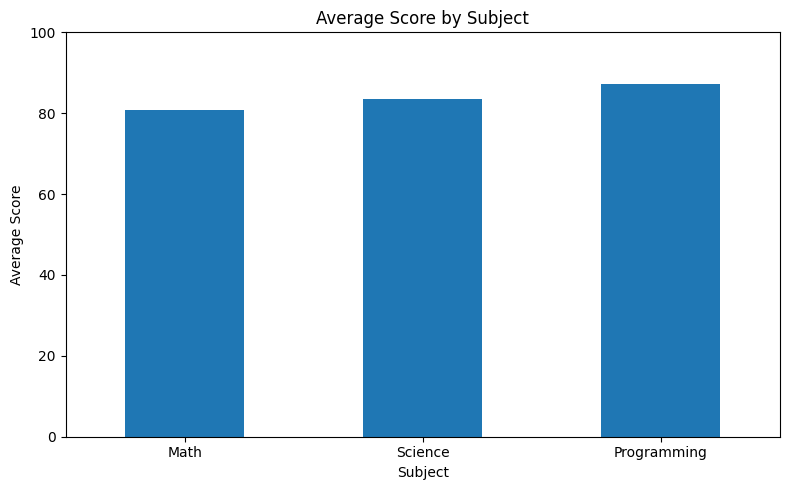

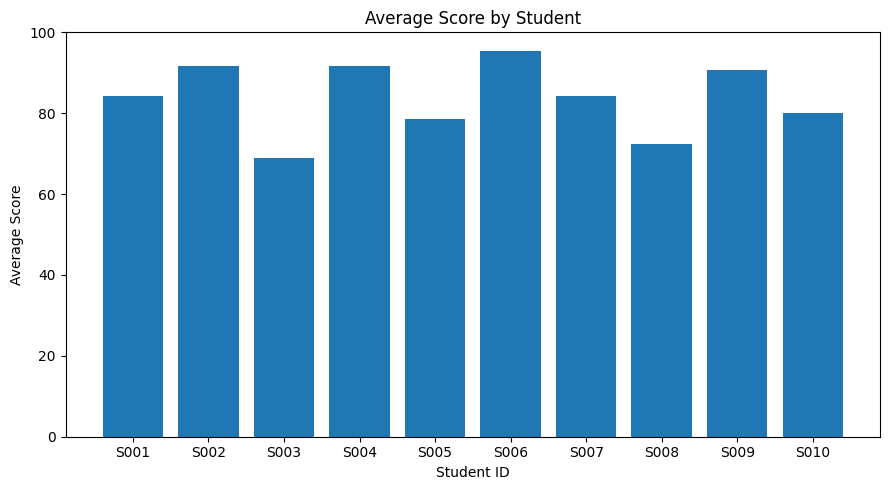

\nAll validation tests passed!
Files saved in: project_results


In [8]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data = {
    "Student_ID": [
        "S001", "S002", "S003", "S004", "S005",
        "S006", "S007", "S008", "S009", "S010"
    ],
    "Math": [78, 92, 65, 88, 74, 95, 81, 69, 90, 76],
    "Science": [85, 89, 72, 91, 80, 93, 84, 75, 87, 79],
    "Programming": [90, 94, 70, 96, 82, 98, 88, 73, 95, 85]}

df = pd.DataFrame(data)
subjects = ["Math", "Science", "Programming"]

df["Average"] = df[subjects].mean(axis=1).round(2)
df["Status"] = df["Average"].apply(
    lambda score: "Pass" if score >= 60 else "Needs Improvement"
)

subject_averages = df[subjects].mean().round(2)
class_average = round(df["Average"].mean(), 2)
top_student = df.loc[df["Average"].idxmax()]

output_dir = Path("project_results")
output_dir.mkdir(exist_ok=True)

df.to_csv(output_dir / "student_results.csv", index=False)
subject_averages.to_csv(output_dir / "subject_averages.csv")

print("STUDENT PERFORMANCE ANALYSIS")
print(df.to_string(index=False))
print("\\nAVERAGE SCORE BY SUBJECT")
print(subject_averages)
print("\\nClass average:", class_average)
print("Top student:", top_student["Student_ID"])
print("Top student's average:", top_student["Average"])
print("Students meeting the pass threshold:",
      int((df["Average"] >= 60).sum()), "/", len(df))

plt.figure(figsize=(8, 5))
subject_averages.plot(kind="bar")
plt.title("Average Score by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Score")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(output_dir / "subject_averages.png", dpi=150)
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(df["Student_ID"], df["Average"])
plt.title("Average Score by Student")
plt.xlabel("Student ID")
plt.ylabel("Average Score")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig(output_dir / "student_averages.png", dpi=150)
plt.show()

assert len(df) == 10
assert df[subjects].ge(0).all().all()
assert df[subjects].le(100).all().all()
assert df["Average"].between(0, 100).all()
assert top_student["Student_ID"] == "S006"
assert (df["Average"] >= 60).all()

print("\\nAll validation tests passed!")
print("Files saved in:", output_dir)

In [9]:
import shutil
from google.colab import files

shutil.make_archive(
    "student_performance_results",
    "zip",
    "project_results"
)

files.download("student_performance_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>